In [1]:
import copy
import random
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms

torch.manual_seed(0)
random.seed(0)
np.random.seed(0)

In [2]:
@dataclass
class Config:
    epochs: int = 500
    refit_epochs: int = 500
    patience: int = 5
    min_epochs: int = 20
    min_delta: float = 1e-4
    batch_size: int = 2048
    lr: float = 1e-2
    max_depth: int = 3
    device: str | None = None
    augment_train: bool = True
    trees_per_class: int = 3  # n: train 10 * n root trees
    ensemble_seed: int = 0

    def __post_init__(self):
        if self.device is None:
            if torch.cuda.is_available():
                self.device = "cuda"
            elif torch.backends.mps.is_available():
                self.device = "mps"
            else:
                self.device = "cpu"
        self.device = torch.device(self.device)

cfg = Config()
print(cfg)

Config(epochs=500, refit_epochs=500, patience=5, min_epochs=20, min_delta=0.0001, batch_size=2048, lr=0.01, max_depth=3, device=device(type='cuda'), augment_train=True, trees_per_class=3, ensemble_seed=0)


In [3]:
def make_loader(dataset, batch_size, shuffle=False, device=None):
    cuda = device is not None and torch.device(device).type == "cuda"
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, pin_memory=cuda, drop_last=False)


def ordered_loader(loader, cfg):
    return DataLoader(loader.dataset, batch_size=cfg.batch_size, shuffle=False,
                      num_workers=0, pin_memory=cfg.device.type == "cuda",
                      drop_last=False, collate_fn=loader.collate_fn)


class BinaryClassDataset(Dataset):

    def __init__(self, base_dataset, class_index, seed=0):
        self.base_dataset = base_dataset
        self.class_index = class_index
        base_labels = dataset_labels(base_dataset).cpu()
        positive_indices = (base_labels == class_index).nonzero(as_tuple=True)[0]
        negative_indices = (base_labels != class_index).nonzero(as_tuple=True)[0]
        positive_count = len(positive_indices)

        generator = torch.Generator().manual_seed(seed)
        selection = torch.randperm(len(negative_indices), generator=generator)[:positive_count]
        sampled_negatives = negative_indices[selection]
        self.indices = torch.cat((positive_indices, sampled_negatives))
        self.labels = (base_labels[self.indices] == class_index).long()

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, _ = self.base_dataset[int(self.indices[index])]
        return image, self.labels[index]

In [4]:
class ChildDataset(Dataset):
    def __init__(self, parent_dataset, indices, labels):
        self.parent_dataset = parent_dataset
        self.indices = indices.tolist()
        self.labels = labels.long().cpu()

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        sample = self.parent_dataset[self.indices[index]]
        if isinstance(sample, dict):
            x = sample["pixel_values"]
        else:
            x, _ = sample
        return x, self.labels[index]

In [5]:
def dataset_labels(dataset):
    if isinstance(dataset, TensorDataset):
        return dataset.tensors[1]
    if isinstance(dataset, (BinaryClassDataset, ChildDataset)):
        return dataset.labels
    raise TypeError("Expected TensorDataset, BinaryClassDataset, or ChildDataset")


pixel_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5] * 3, std=[0.5] * 3),
])

cifar_augmentation = transforms.Compose([
    transforms.RandomCrop(
        size=32,
        padding=4,
        padding_mode="reflect",
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.2),
])

def augment_cifar_batch(x):
    if x.shape[0] == 0:
        return x.clone()

    return cifar_augmentation(x)

def cache_cifar_images(hf_split, batch_size=128):
    images = torch.empty((len(hf_split), 3, 32, 32), dtype=torch.float32)
    labels = torch.empty(len(hf_split), dtype=torch.long)
    for start in range(0, len(hf_split), batch_size):
        batch = hf_split[start:start + batch_size]
        x = torch.stack([pixel_transform(image.convert("RGB")) for image in batch["img"]])
        end = start + len(x)
        images[start:end].copy_(x)
        labels[start:end] = torch.tensor(batch["label"], dtype=torch.long)
    return TensorDataset(images, labels)

In [6]:
class SharedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
        )
        self.feature_dim = 8 * 4 * 4

    def forward(self, x):
        return self.features(x)


class TreeNode(nn.Module):
    def __init__(self, shared_cnn):
        super().__init__()
        self.head = nn.Sequential(
            nn.Linear(shared_cnn.feature_dim, 16), nn.ReLU(),
            nn.Linear(16, 1),
        )
        self.cnn_snapshot = copy.deepcopy(shared_cnn)
        self.cnn_snapshot.requires_grad_(False)
        self.cnn_snapshot.eval()
        self.left_branch = None
        self.right_branch = None
        self.left_wgt = nn.Parameter(torch.tensor(0.0))
        self.right_wgt = nn.Parameter(torch.tensor(0.0))

    def add_corrections(self, base_score, x):
        with torch.no_grad():
            left = ((self.left_branch(x, augment=False) >= 0).to(x.dtype)
                    if self.left_branch is not None else None)
            right = ((self.right_branch(x, augment=False) >= 0).to(x.dtype)
                     if self.right_branch is not None else None)
        score = base_score
        if left is not None:
            score = score + self.left_wgt.clamp_min(0) * left
        if right is not None:
            score = score - self.right_wgt.clamp_min(0) * right
        return score

    def forward_training(self, x, shared_cnn, augment=False):
        node_x = augment_cifar_batch(x) if augment else x
        base = self.head(shared_cnn(node_x)).squeeze(-1)
        return self.add_corrections(base, node_x)

    def forward(self, x, augment=False):
        node_x = augment_cifar_batch(x) if augment else x
        base = self.head(self.cnn_snapshot(node_x)).squeeze(-1)
        return self.add_corrections(base, node_x)

    @torch.no_grad()
    def save_cnn_snapshot(self, shared_cnn):
        self.cnn_snapshot.load_state_dict(shared_cnn.state_dict())
        self.cnn_snapshot.requires_grad_(False)
        self.cnn_snapshot.eval()

In [7]:
@torch.no_grad()
def evaluate(node, loader, cfg, shared_cnn=None, pos_weight=None):
    node.eval()
    if shared_cnn is not None:
        shared_cnn.eval()
    count = 0
    true_positive = false_positive = false_negative = 0
    errors = torch.zeros((), dtype=torch.long, device=cfg.device)
    loss_sum = torch.zeros((), device=cfg.device)
    for x, y in loader:
        x = x.to(cfg.device, non_blocking=True)
        y = y.to(cfg.device, dtype=torch.float32, non_blocking=True).reshape(-1)
        logits = node(x) if shared_cnn is None else node.forward_training(x, shared_cnn)
        count += y.numel()
        pred = logits >= 0
        target = y.bool()
        errors += (pred != target).sum()
        true_positive += int((pred & target).sum().item())
        false_positive += int((pred & ~target).sum().item())
        false_negative += int((~pred & target).sum().item())
        loss_sum += F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight, reduction="sum")
    errors = errors.item()
    return {"errors": errors, "accuracy": 1-errors/count,
            "loss": loss_sum.item()/count, "count": count,
            "precision": true_positive / max(true_positive + false_positive, 1),
            "recall": true_positive / max(true_positive + false_negative, 1)}

In [8]:
def fit_node(node, dataloader, cfg, shared_cnn, name="", epochs=None):
    node.to(cfg.device)
    shared_cnn.to(cfg.device)
    shared_cnn.load_state_dict(node.cnn_snapshot.state_dict())
    shared_cnn.requires_grad_(True)
    for branch in (node.left_branch, node.right_branch):
        if branch is not None:
            branch.requires_grad_(False)
            branch.eval()

    params = (list(shared_cnn.parameters()) + list(node.head.parameters())
              + [node.left_wgt, node.right_wgt])
    optimizer = torch.optim.Adam(params, lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        threshold=cfg.min_delta,
        threshold_mode="abs",
        min_lr=5*1e-5,
    )
    scan = ordered_loader(dataloader, cfg)
    labels = dataset_labels(dataloader.dataset)
    total = labels.numel()
    pos = int((labels == 1).sum().item())
    pos_weight = torch.tensor(max(total-pos,1)/max(pos,1),
                              dtype=torch.float32, device=cfg.device)
    with torch.no_grad():
        node.left_wgt.clamp_(min=0)
        node.right_wgt.clamp_(min=0)

    def snapshot():
        return (copy.deepcopy(shared_cnn.state_dict()),
                copy.deepcopy(node.head.state_dict()),
                node.left_wgt.detach().clone(), node.right_wgt.detach().clone())

    initial = evaluate(node, scan, cfg, shared_cnn=shared_cnn,
                       pos_weight=pos_weight)
    best_loss = initial["loss"]
    scheduler.step(best_loss)
    patience_reference = best_loss
    best_state = snapshot()
    early_stop = 0
    for epoch in range(cfg.epochs if epochs is None else epochs):
        shared_cnn.train()
        node.head.train()
        for x, y in dataloader:
            x = x.to(cfg.device, non_blocking=True)
            y = y.to(cfg.device, dtype=torch.float32, non_blocking=True).reshape(-1)
            optimizer.zero_grad(set_to_none=True)
            logits = node.forward_training(x, shared_cnn, augment=cfg.augment_train)
            loss = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
            loss.backward()
            optimizer.step()
            with torch.no_grad():
                node.left_wgt.clamp_(min=0)
                node.right_wgt.clamp_(min=0)
        metrics = evaluate(node, scan, cfg, shared_cnn=shared_cnn,
                           pos_weight=pos_weight)
        current_loss = metrics["loss"]

        if current_loss < best_loss:
            best_loss = current_loss
            best_state = snapshot()

        if current_loss < patience_reference - cfg.min_delta:
            patience_reference = current_loss
            early_stop = 0
        else:
            early_stop += 1

        previous_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(current_loss)
        current_lr = optimizer.param_groups[0]["lr"]
        
        if current_lr < previous_lr:
            early_stop = 0
            print(f"{name}: learning rate {previous_lr:.2e} -> {current_lr:.2e}")

        print(f"{name} epoch {epoch+1}: accuracy={metrics['accuracy']:.2%}, "
              f"errors={metrics['errors']}, weighted BCE={current_loss:.4f}, "
              f"patience={early_stop}/{cfg.patience}")
        if early_stop >= cfg.patience and epoch + 1 >= cfg.min_epochs:
            print(f"{name}: early stopping; best weighted BCE={best_loss:.6f}")
            break

    shared_cnn.load_state_dict(best_state[0])
    node.head.load_state_dict(best_state[1])
    with torch.no_grad():
        node.left_wgt.copy_(best_state[2])
        node.right_wgt.copy_(best_state[3])
    node.save_cnn_snapshot(shared_cnn)
    shared_cnn.eval()
    return node.eval()

In [9]:
@torch.no_grad()
def make_child_loaders(node, parent_loader, cfg):
    scan_loader = DataLoader(
        parent_loader.dataset,
        batch_size=cfg.batch_size,
        shuffle=False,
        drop_last=False,
        collate_fn=parent_loader.collate_fn,
    )

    node.eval()

    predictions, labels = [], []
    for x, target in scan_loader:
        score = node(x.to(cfg.device), augment=False).reshape(-1)
        predictions.append((score >= 0).cpu())
        labels.append(target.reshape(-1).cpu().bool())

    pred = torch.cat(predictions)
    y = torch.cat(labels)

    false_negative = ~pred & y
    false_positive = pred & ~y

    left_mask = ~(pred & y)
    right_mask = pred | y

    def build_loader(mask, targets):
        indices = mask.nonzero(as_tuple=True)[0]

        child_dataset = ChildDataset(
            parent_dataset=parent_loader.dataset,
            indices=indices,
            labels=targets[indices],
        )

        return DataLoader(
            child_dataset,
            batch_size=cfg.batch_size,
            shuffle=True,
            drop_last=False,
        )

    left_loader = (
        build_loader(left_mask, false_negative)
        if false_negative.any()
        else None
    )

    right_loader = (
        build_loader(right_mask, false_positive)
        if false_positive.any()
        else None
    )

    return left_loader, right_loader

In [10]:
def fit_tree(dataloader, cfg, shared_cnn, depth=0, name="root"):
    node = TreeNode(shared_cnn).to(cfg.device)
    node = fit_node(node, dataloader, cfg, shared_cnn, name=name)
    if depth >= cfg.max_depth:
        return node.eval()
    left_loader, right_loader = make_child_loaders(node, dataloader, cfg)
    if left_loader is None and right_loader is None:
        return node.eval()
    if left_loader is not None:
        node.left_branch = fit_tree(left_loader, cfg, shared_cnn, depth+1, name+"-left")
        node.left_branch.requires_grad_(False)
    if right_loader is not None:
        node.right_branch = fit_tree(right_loader, cfg, shared_cnn, depth+1, name+"-right")
        node.right_branch.requires_grad_(False)
    return fit_node(node, dataloader, cfg, shared_cnn, name=name+" refit", epochs=cfg.refit_epochs)

In [11]:
class OneVsAllVotingTrees(nn.Module):
    def __init__(self, trees_by_class):
        super().__init__()
        self.trees_per_class = len(trees_by_class[0])
        self.trees = nn.ModuleList([nn.ModuleList(group) for group in trees_by_class])

    def forward(self, images):
        return torch.stack([
            torch.stack([tree(images) for tree in group], dim=1)
            for group in self.trees
        ], dim=1)

    @staticmethod
    def aggregate_votes(scores):
        votes = (scores >= 0).sum(dim=2)  # One positive vote for the tree's class.
        mean_logits = scores.mean(dim=2)
        tied = votes == votes.max(dim=1, keepdim=True).values
        prediction = mean_logits.masked_fill(~tied, -torch.inf).argmax(dim=1)
        return {"prediction": prediction, "votes": votes, "mean_logits": mean_logits, "vote_tie": tied.sum(dim=1) > 1}

    @torch.no_grad()
    def predict(self, images):
        return self.aggregate_votes(self(images))["prediction"]

def fit_one_vs_all(train_dataset, cfg, class_names):
    trees_by_class, tree_seeds = [], []
    for class_index, class_name in enumerate(class_names):
        group, seeds = [], []
        for member_index in range(cfg.trees_per_class):
            seed = (cfg.ensemble_seed + class_index * cfg.trees_per_class
                    + member_index) % (2**32)
            torch.manual_seed(seed)
            random.seed(seed)
            np.random.seed(seed)
            binary_dataset = BinaryClassDataset(train_dataset, class_index, seed=seed)
            positive_count = int(binary_dataset.labels.sum().item())
            print(f"\nClass {class_index}: {class_name} versus all; "
                  f"tree {member_index + 1}/{cfg.trees_per_class}, seed={seed}; "
                  f"samples={positive_count} positive + "
                  f"{len(binary_dataset) - positive_count} negative")
            shared_cnn = SharedCNN().to(cfg.device)
            loader = make_loader(binary_dataset, cfg.batch_size,
                                 shuffle=True, device=cfg.device)
            tree = fit_tree(loader, cfg, shared_cnn,
                            name=f"{class_index}:{class_name}/tree-{member_index + 1}")
            tree.requires_grad_(False)
            group.append(tree.eval())
            seeds.append(seed)
            del shared_cnn
        trees_by_class.append(group)
        tree_seeds.append(seeds)
    model = OneVsAllVotingTrees(trees_by_class).to(cfg.device).eval()
    model.tree_seeds = tree_seeds
    return model

@torch.no_grad()
def evaluate_multiclass(model, loader, cfg):
    model.eval()
    classes = torch.arange(10, device=cfg.device)
    confusion = torch.zeros(10, 10, dtype=torch.long)
    binary_tp = torch.zeros(10, dtype=torch.long)
    binary_fp = torch.zeros(10, dtype=torch.long)
    binary_fn = torch.zeros(10, dtype=torch.long)
    binary_errors = torch.zeros(10, dtype=torch.long)
    loss_sum = torch.zeros(10, dtype=torch.float64)
    count = zero_votes = multiple_classes = vote_ties = 0
    winning_votes_sum = 0
    n = model.trees_per_class
    for x, y in loader:
        x = x.to(cfg.device, non_blocking=True)
        y = y.to(cfg.device, dtype=torch.long, non_blocking=True)
        scores = model(x)
        outcome = model.aggregate_votes(scores)
        pred, votes = outcome["prediction"], outcome["votes"]
        target = (y[:, None, None] == classes[None, :, None]).expand_as(scores)
        binary_pred = scores >= 0
        confusion += torch.bincount((y * 10 + pred).cpu(), minlength=100).reshape(10, 10)
        binary_tp += (binary_pred & target).sum(dim=(0, 2)).cpu()
        binary_fp += (binary_pred & ~target).sum(dim=(0, 2)).cpu()
        binary_fn += (~binary_pred & target).sum(dim=(0, 2)).cpu()
        binary_errors += (binary_pred != target).sum(dim=(0, 2)).cpu()
        loss_sum += F.binary_cross_entropy_with_logits(
            scores, target.to(scores.dtype), reduction="none").sum(dim=(0, 2)).cpu().double()
        zero_votes += int((votes.sum(dim=1) == 0).sum().item())
        multiple_classes += int(((votes > 0).sum(dim=1) > 1).sum().item())
        vote_ties += int(outcome["vote_tie"].sum().item())
        winning_votes_sum += int(votes.gather(1, pred[:, None]).sum().item())
        count += len(y)
    return {
        "count": count,
        "accuracy": confusion.diag().sum().item() / count,
        "errors": count - confusion.diag().sum().item(),
        "confusion_matrix": confusion,
        "trees_per_class": n,
        "binary_accuracy": 1 - binary_errors.double() / (count * n),
        "binary_bce": loss_sum / (count * n),
        "binary_precision": binary_tp.double() / (binary_tp + binary_fp).clamp_min(1),
        "binary_recall": binary_tp.double() / (binary_tp + binary_fn).clamp_min(1),
        "voting_class_recall": confusion.diag().double() / confusion.sum(1).clamp_min(1),
        "zero_positive_votes": zero_votes,
        "multiple_voted_classes": multiple_classes,
        "vote_ties": vote_ties,
        "mean_winning_votes": winning_votes_sum / count,
    }


def report_metrics(title, metrics, class_names):
    print(f"{title}: voting accuracy={metrics['accuracy']:.2%}, "
          f"errors={metrics['errors']}/{metrics['count']}")
    print("Binary diagnostics pool all member trees for each class.")
    print("class         binary acc  binary BCE  precision  recall  voting recall")
    for i, name in enumerate(class_names):
        print(f"{name:12} {metrics['binary_accuracy'][i]:10.2%} "
              f"{metrics['binary_bce'][i]:11.4f} "
              f"{metrics['binary_precision'][i]:10.2%} "
              f"{metrics['binary_recall'][i]:7.2%} "
              f"{metrics['voting_class_recall'][i]:13.2%}")
    print("Examples with no positive votes:", metrics['zero_positive_votes'])
    print("Examples with votes for multiple classes:", metrics['multiple_voted_classes'])
    print("Examples requiring a vote-count tie-break:", metrics['vote_ties'])
    print(f"Mean winning vote count: {metrics['mean_winning_votes']:.2f} / "
          f"{metrics['trees_per_class']}")


In [12]:
dataset = load_dataset("uoft-cs/cifar10")
assert len(dataset["train"]) == 50_000
assert len(dataset["test"]) == 10_000
class_names = dataset["train"].features["label"].names
assert len(class_names) == 10

train_dataset = cache_cifar_images(dataset["train"])
test_dataset = cache_cifar_images(dataset["test"])
train_loader = make_loader(train_dataset, cfg.batch_size, device=cfg.device)
test_loader = make_loader(test_dataset, cfg.batch_size, device=cfg.device)
print("Classes:", class_names)
print("Cached training images:", train_dataset.tensors[0].shape)
print("Cached test images:", test_dataset.tensors[0].shape)
print("Train class counts:", torch.bincount(train_dataset.tensors[1], minlength=10))
print("Test class counts:", torch.bincount(test_dataset.tensors[1], minlength=10))

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Cached training images: torch.Size([50000, 3, 32, 32])
Cached test images: torch.Size([10000, 3, 32, 32])
Train class counts: tensor([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000])
Test class counts: tensor([1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000])


In [13]:
model = fit_one_vs_all(train_dataset, cfg, class_names)

node_counts = {
    class_name: [sum(isinstance(m, TreeNode) for m in tree.modules()) for tree in group]
    for class_name, group in zip(class_names, model.trees)
}
print("Root trees per class:", model.trees_per_class)
print("Total root trees:", sum(len(group) for group in model.trees))
print("Nodes per tree (member order):", node_counts)
print("Total nodes:", sum(sum(counts) for counts in node_counts.values()))
print("Tree seeds:", dict(zip(class_names, model.tree_seeds)))
print("Inference ensemble parameters (including snapshots):", sum(p.numel() for p in model.parameters()))



Class 0: airplane versus all; tree 1/3, seed=0; samples=5000 positive + 5000 negative
0:airplane/tree-1 epoch 1: accuracy=59.75%, errors=4025, weighted BCE=0.6734, patience=0/5
0:airplane/tree-1 epoch 2: accuracy=66.42%, errors=3358, weighted BCE=0.6005, patience=0/5
0:airplane/tree-1 epoch 3: accuracy=72.73%, errors=2727, weighted BCE=0.5697, patience=0/5
0:airplane/tree-1 epoch 4: accuracy=74.40%, errors=2560, weighted BCE=0.5445, patience=0/5
0:airplane/tree-1 epoch 5: accuracy=74.12%, errors=2588, weighted BCE=0.5429, patience=0/5
0:airplane/tree-1 epoch 6: accuracy=74.68%, errors=2532, weighted BCE=0.5353, patience=0/5
0:airplane/tree-1 epoch 7: accuracy=75.00%, errors=2500, weighted BCE=0.5314, patience=0/5
0:airplane/tree-1 epoch 8: accuracy=75.27%, errors=2473, weighted BCE=0.5264, patience=0/5
0:airplane/tree-1 epoch 9: accuracy=75.46%, errors=2454, weighted BCE=0.5204, patience=0/5
0:airplane/tree-1 epoch 10: accuracy=75.51%, errors=2449, weighted BCE=0.5172, patience=0/5
0:

Training: voting accuracy=61.36%, errors=19319/50000
Binary diagnostics pool all member trees for each class.
class         binary acc  binary BCE  precision  recall  voting recall
airplane         83.40%      0.3504     36.24%  87.01%        64.16%
automobile       84.32%      0.3342     38.08%  90.75%        74.08%
bird             75.84%      0.4911     26.18%  77.81%        43.18%
cat              73.25%      0.4844     24.99%  83.66%        41.74%
deer             78.49%      0.4424     29.18%  80.67%        50.46%
dog              78.29%      0.4350     29.53%  84.47%        55.66%
frog             83.98%      0.3428     37.35%  88.86%        75.06%
horse            83.22%      0.3817     35.60%  83.85%        66.40%
ship             86.85%      0.2960     42.56%  90.02%        75.42%
truck            79.13%      0.4185     31.01%  88.75%        67.46%
Examples with no positive votes: 4
Examples with votes for multiple classes: 49228
Examples requiring a vote-count tie-break: 334

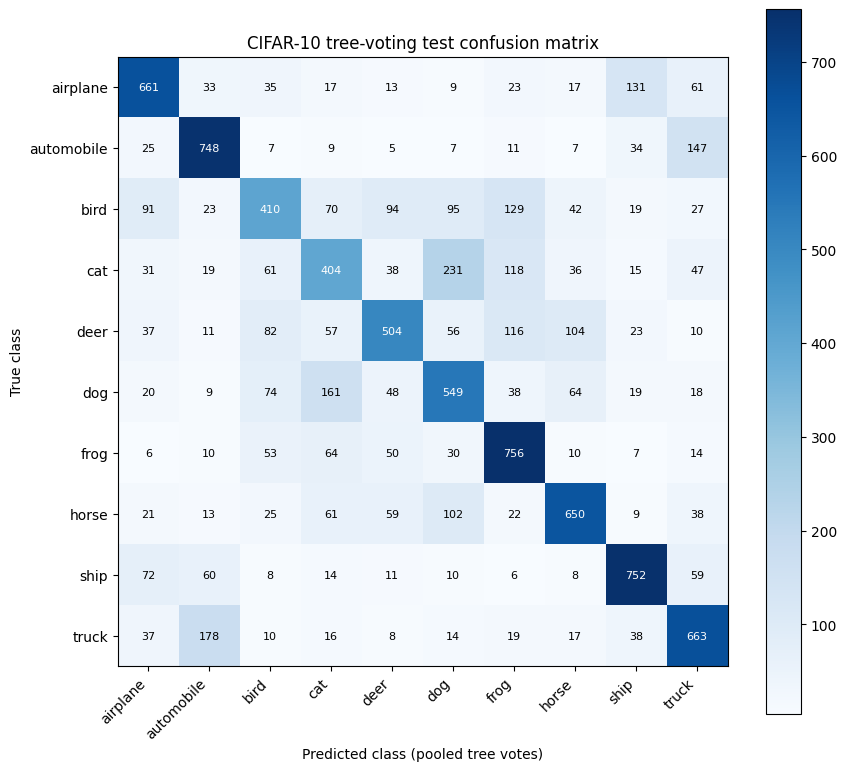

In [14]:
train_metrics = evaluate_multiclass(model, train_loader, cfg)
test_metrics = evaluate_multiclass(model, test_loader, cfg)
report_metrics("Training", train_metrics, class_names)
print()
report_metrics("Official test", test_metrics, class_names)

fig, ax = plt.subplots(figsize=(9, 8))
confusion = test_metrics["confusion_matrix"].numpy()
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_yticks(range(10), class_names)
ax.set_xlabel("Predicted class (pooled tree votes)")
ax.set_ylabel("True class")
ax.set_title("CIFAR-10 tree-voting test confusion matrix")
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(confusion[i, j]), ha="center", va="center",
                color="white" if confusion[i, j] > confusion.max() / 2 else "black",
                fontsize=8)
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()